<a href="https://colab.research.google.com/github/DheaAprilya/Pengolahan-Citra-Digital/blob/main/PCD7_DheaAprilya_20240040136_TI24E.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

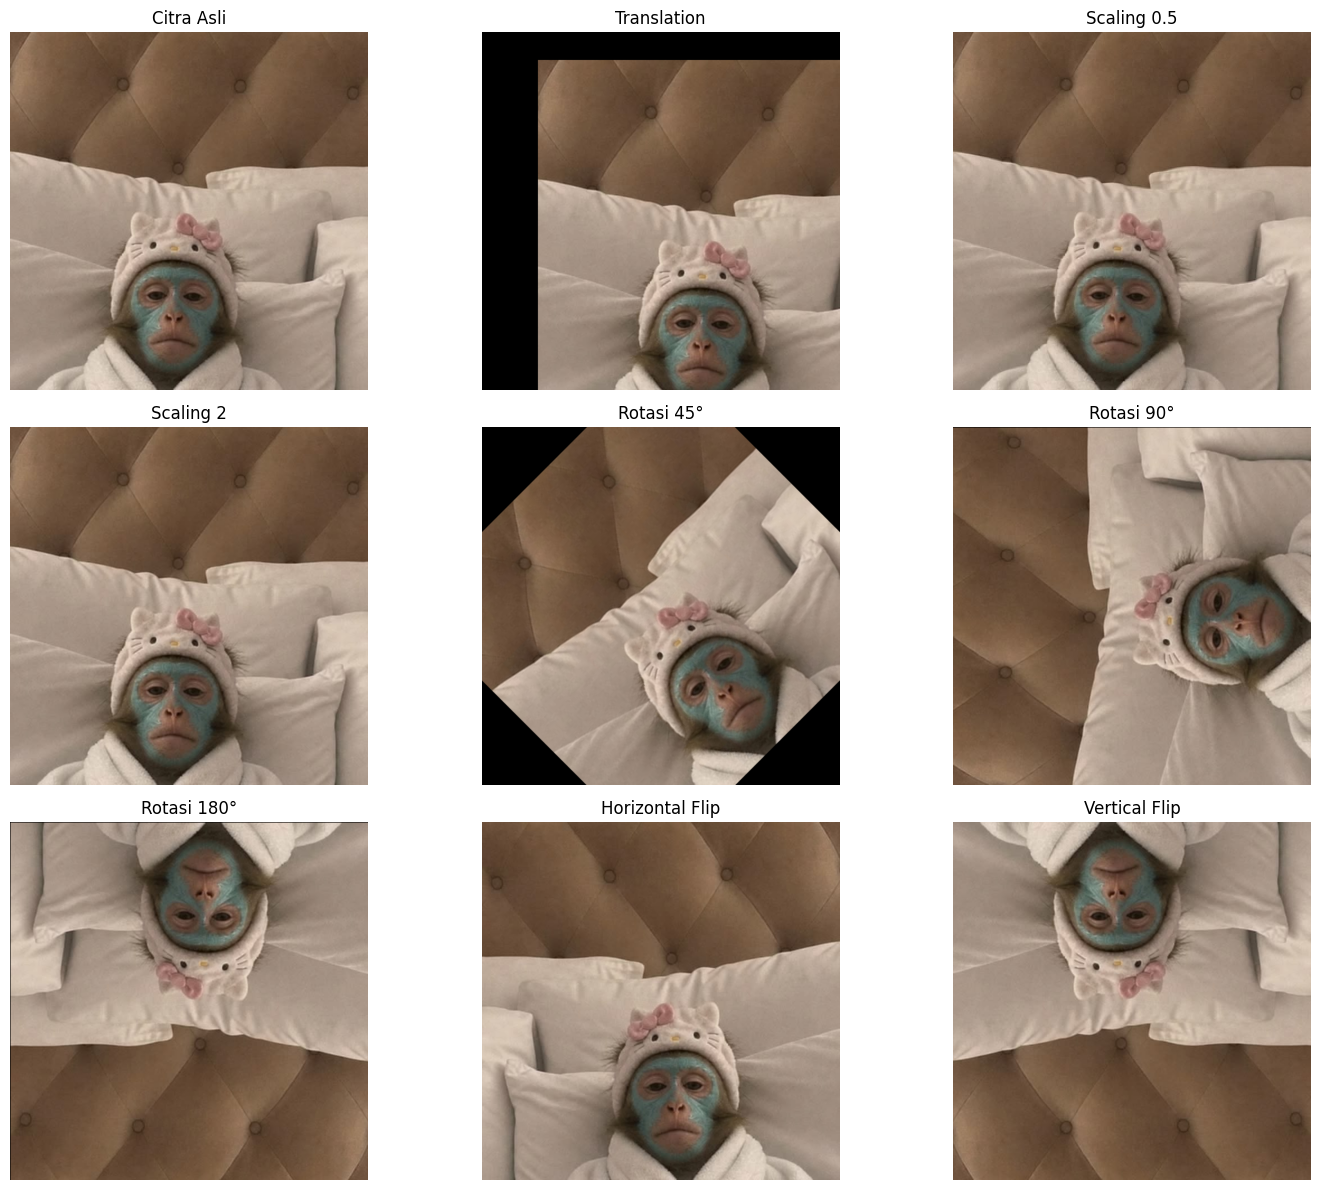

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca gambar (ganti dengan nama file gambarmu, JPG/PNG)
img = cv2.imread("/content/monyet.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img.shape[:2]

# 2. Translation (geser 100 px ke kanan, 50 px ke bawah)
tx, ty = 100, 50
M_trans = np.float32([[1, 0, tx],
                      [0, 1, ty]])
translasi = cv2.warpAffine(img, M_trans, (w, h))

# 3. Scaling (faktor 0.5 dan 2)
scale_05 = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
scale_2 = cv2.resize(img, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)

# 4. Rotation (45, 90, 180 derajat) di sekitar titik tengah
def rotasi(image, sudut):
    h, w = image.shape[:2]
    pusat = (w // 2, h // 2)
    M = cv2.getRotationMatrix2D(pusat, sudut, 1.0)
    return cv2.warpAffine(image, M, (w, h))

rot_45 = rotasi(img, 45)
rot_90 = rotasi(img, 90)
rot_180 = rotasi(img, 180)

# 5. Flip
flip_h = cv2.flip(img, 1)   # horizontal
flip_v = cv2.flip(img, 0)   # vertical

# 6. Tampilkan semua hasil
hasil = [
    ("Citra Asli", img),
    ("Translation", translasi),
    ("Scaling 0.5", scale_05),
    ("Scaling 2", scale_2),
    ("Rotasi 45°", rot_45),
    ("Rotasi 90°", rot_90),
    ("Rotasi 180°", rot_180),
    ("Horizontal Flip", flip_h),
    ("Vertical Flip", flip_v),
]

plt.figure(figsize=(15, 12))
for i, (judul, gambar) in enumerate(hasil):
    plt.subplot(3, 3, i + 1)
    plt.imshow(gambar)
    plt.title(judul)
    plt.axis("off")
plt.tight_layout()
plt.savefig("hasil_transformasi.png", dpi=150)
plt.show()